# median+BCH vs E8 lattice — matched comparison

Both schemes on the same embeddings, the same enrollment split, the same
held-out packets, and same-environment impostors. The quantizer and the error
correcting code are the only things that differ.

**Change from the standalone BCH replication.** That notebook authenticated one
packet against one packet, which scored ~50.7% balanced accuracy — chance.
Intra-distances of 188/366/282/360 against inter-distances of 52/114/374/366
overlap completely, where the paper reports intra below 50 and inter above 100.
Here the baseline averages packets exactly as the lattice pipeline does. That
is the only comparison a reviewer will accept.

Conditions: `clean` (held-out residential), `A`, `F`.

## Setup

In [ ]:
USE_SYNTHETIC = False

REPO_DIR  = "/content/LoRa_RFFI"
DRIVE_DIR = "/content/drive/MyDrive/lora_rffi"

F_BACKGROUND = f"{DRIVE_DIR}/dataset_seen_devices.h5"   # devices 1-30
F_TARGET     = f"{DRIVE_DIR}/dataset_residential.h5"    # devices 31-40
F_IMPOSTOR   = f"{DRIVE_DIR}/dataset_rogue.h5"          # devices 41-45
EXTRACTOR    = f"{DRIVE_DIR}/Extractor_1.h5"
CACHE_DIR    = f"{DRIVE_DIR}/emb_cache"

N_ENROLL = 200
N_VERIFY = 16
SEED     = 0

# E8 pipeline (v1 operating point, unchanged)
E8_NKEEP, E8_MARGIN = 64, 0.5

# BCH sweep. t is swept for free once distances are collected.
T_VALUES = list(range(0, 260, 5))
FAR_CEILING = 1e-3        # baseline reported at its best t subject to this


In [ ]:
import os, sys
import numpy as np

if not USE_SYNTHETIC:
    from google.colab import drive
    drive.mount("/content/drive")

    # Only need the repo for dataset_preparation.py (LoadDataset and the
    # channel-independent spectrogram). The data and model come from Drive.
    if not os.path.isdir(REPO_DIR):
        !git clone -q https://github.com/gxhen/LoRa_RFFI.git {REPO_DIR}
    sys.path.insert(0, REPO_DIR)

    # Extractor_1.h5 is a legacy Keras model and Colab ships Keras 3, which
    # refuses to load it. tf_keras is the 2.x compatibility shim.
    !pip -q install tf_keras h5py

    os.makedirs(CACHE_DIR, exist_ok=True)

Mounted at /content/drive


### Precheck the data

Check the uploads. This also prints the device label range in each HDF5: labels are 0-based, so `dataset_residential.h5` should report 30-39,
not 31-40

In [ ]:
if not USE_SYNTHETIC:
    import h5py

    ok = True
    for path in [F_BACKGROUND, F_TARGET, F_IMPOSTOR, EXTRACTOR]:
        exists = os.path.exists(path)
        ok &= exists
        size = f"{os.path.getsize(path)/1e6:8.1f} MB" if exists else "  MISSING"
        print(f"{'OK ' if exists else 'X  '} {size}  {path}")

    # The repo may or may not ship the pretrained extractor depending on when it
    # was cloned. If it's in the repo, fall back to that copy.
    if not os.path.exists(EXTRACTOR):
        fallback = f"{REPO_DIR}/models/Extractor_1.h5"
        if os.path.exists(fallback):
            EXTRACTOR = fallback
            print(f"\n-> using extractor from the repo instead: {EXTRACTOR}")
            ok = True

    assert ok, "upload the missing files to DRIVE_DIR before continuing"

    print()
    for path in [F_BACKGROUND, F_TARGET, F_IMPOSTOR]:
        with h5py.File(path, "r") as f:
            lab = np.array(f["label"]).ravel()
            devs = np.unique(lab)
            print(f"{os.path.basename(path):32s} data{f['data'].shape}  "
                  f"labels {devs.min()}-{devs.max()}  "
                  f"({len(devs)} devices, {len(lab)//len(devs)} pkt/dev)")

OK    1573.2 MB  /content/drive/MyDrive/lora_rffi/dataset_seen_devices.h5
OK     524.4 MB  /content/drive/MyDrive/lora_rffi/dataset_residential.h5
OK     131.1 MB  /content/drive/MyDrive/lora_rffi/dataset_rogue.h5
OK      49.9 MB  /content/drive/MyDrive/lora_rffi/Extractor_1.h5

dataset_seen_devices.h5          data(12000, 16384)  labels 1.0-30.0  (30 devices, 400 pkt/dev)
dataset_residential.h5           data(4000, 16384)  labels 31.0-40.0  (10 devices, 400 pkt/dev)
dataset_rogue.h5                 data(1000, 16384)  labels 41.0-45.0  (5 devices, 200 pkt/dev)


### E8 pipeline (v1)

In [ ]:
%%writefile fuzzy_eval.py
"""
fuzzy_eval.py

Lattice fuzzy extractor over LoRa RF fingerprints -- GAR/FAR evaluation only.

Pipeline: embedding -> whitening -> pruning -> E8
          -> code-offset sketch -> 128-bit key + verify hash
"""

import hashlib
import hmac
from dataclasses import dataclass

import numpy as np


# ===========================================================================
# E8 lattice
# ===========================================================================
# E8 is the union of D8 and D8 shifted by (1/2,...,1/2). In this scaling the
# minimum distance between lattice points is sqrt(2), so a point can move up to
# sqrt(2)/2 in any direction before the nearest-point search starts returning a
# different answer. That radius is the error-tolerance of the
# scheme -- calibrate_beta() tries to stay inside the radius
#
# Nearest-point algorithm is Conway & Sloane (1982): quantise to D8 twice, once
# on the raw vector and once on the vector shifted by 1/2, then keep whichever
# is closer

PACKING_RADIUS = np.sqrt(2.0) / 2.0


def _closest_d8(x):
    """Nearest point of D8 = integer vectors with even coordinate sum."""
    f = np.rint(x)
    delta = x - f
    worst = np.argmax(np.abs(delta), axis=-1)[..., None]
    dj = np.take_along_axis(delta, worst, -1)
    fj = np.take_along_axis(f, worst, -1)
    flipped = f.copy()
    np.put_along_axis(flipped, worst, np.where(dj >= 0, fj + 1, fj - 1), -1)
    sum_is_even = (np.mod(f.sum(-1), 2) == 0)
    return np.where(sum_is_even[..., None], f, flipped)


def closest_e8(x):
    """Nearest E8 point. Takes (..., 8), returns (..., 8)."""
    x = np.asarray(x, dtype=float)
    assert x.shape[-1] == 8, "E8 works on blocks of 8 dims"
    a = _closest_d8(x)
    b = _closest_d8(x - 0.5) + 0.5
    da = ((x - a) ** 2).sum(-1)
    db = ((x - b) ** 2).sum(-1)
    return np.where((da <= db)[..., None], a, b)


def _points_to_bytes(pts):
    """byte encoding of E8 points, for hashing.

    Every E8 coordinate is either an integer or a half-integer, so doubling
    gives integers and removes any float formatting. This matters
    because enrollment and verification must hash to identical bytes or the key
    fails to reproduce
    """
    return np.rint(np.asarray(pts) * 2).astype(np.int64).tobytes()


# ===========================================================================
# Stage 1: whitening + Fisher ranking
# ===========================================================================
class Whitener:
    """Whiten by the pooled within-device covariance, then rank dims by how
    well they separate devices

    Using this instead of sklearn's LDA because: LDA gives
    at most (n_classes - 1) components, so with 30 devices we get cap
    29 dims and we want 64 (for e8 lattice). Whitening has no such limit. Same
    underlying idea -- flatten the within-device noise to unit variance in every
    direction, after which a dimension's between-device variance is its Fisher
    ratio

    Fitted on background devices only. Never on a device we're going to enroll
    """

    def __init__(self, pca_dim=200, shrinkage=0.1):
        self.pca_dim = pca_dim
        self.shrinkage = shrinkage

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).ravel()

        self.mean_ = X.mean(0)
        Xc = X - self.mean_

        if self.pca_dim and self.pca_dim < X.shape[1]:
            _, _, Vt = np.linalg.svd(Xc, full_matrices=False)
            self.pca_ = Vt[:self.pca_dim].T
        else:
            self.pca_ = np.eye(X.shape[1])
        Z = Xc @ self.pca_

        devices = np.unique(y)
        d = Z.shape[1]

        # Pooled within-device scatter: how much a single device's packets
        # moves around that device's own mean
        Sw = np.zeros((d, d))
        for dev in devices:
            Zd = Z[y == dev]
            Zd = Zd - Zd.mean(0)
            Sw += Zd.T @ Zd
        Sw /= max(len(Z) - len(devices), 1)
        Sw = (1 - self.shrinkage) * Sw + self.shrinkage * (np.trace(Sw) / d) * np.eye(d)

        # Whitening transform = eigendecomp scaled by 1/sqrt(eigenvalue)
        evals, evecs = np.linalg.eigh(Sw)
        evals = np.maximum(evals, 1e-12)      # guard against tiny negatives
        self.W_ = evecs / np.sqrt(evals)

        # Score every output dim. After whitening within-variance is ~1
        # everywhere, so between-device variance tells which dims
        # actually carry device identity
        Zw = Z @ self.W_
        means = np.stack([Zw[y == dev].mean(0) for dev in devices])
        self.between_ = means.var(0, ddof=1)
        self.rank_ = np.argsort(-self.between_)       # best dims first
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.mean_) @ self.pca_ @ self.W_

    @property
    def out_dim(self):
        return self.W_.shape[1]


# ===========================================================================
# Stage 2: pruning
# ===========================================================================
def pick_dims(z_enroll, proj, n_keep=64, n_candidates=None):
    """Choose which projected dims to build this device's key from.

    Two-stage filter. First take the globally most discriminative dims from the
    background population (proj.rank_). Then, among those, prefer the ones that
    are stable *for this specific device* -- a dim can separate devices well on
    average and still be jittery on one particular unit, and that unit is the
    one we're enrolling.

    n_keep must be a multiple of 8 so the dims tile exactly into E8 blocks.

    The chosen indices go in the public helper data. That may leak a little
    about the device but it shouldn't leak the whole key - still need additional checking
    """
    assert n_keep % 8 == 0, "n_keep must be a multiple of 8"
    n_candidates = n_candidates or min(4 * n_keep, proj.out_dim)

    cand = proj.rank_[:n_candidates]
    jitter = z_enroll[:, cand].var(0, ddof=1)
    score = proj.between_[cand] / (jitter + 1e-12)      # per-device Fisher ratio

    keep = cand[np.argsort(-score)[:n_keep]]
    return np.sort(keep)        # sort so the ordering is deterministic


# ===========================================================================
# Stage 3: lattice
# ===========================================================================
def calibrate_beta(z_enroll, dims, n_verify, margin=0.5, n_boot=400,
                   quantile=0.95, seed=0):
    """Pick the lattice scale beta from the device's own enrollment packets.


    At verification we average n_verify packets. That average won't land exactly
    on the enrollment centroid -- it may land somewhere nearby, and how near depends
    on the device's noise. So: using a few hundred fake verification
    attempts out of the enrollment packets, measure how far each one drifts from
    the centroid (per 8-dim block, since each block is quantised independently),
    and take the 95th percentile

    Then scale the lattice so that radius sits at `margin` x the packing radius.

        margin small (0.3) -> beta large -> roomy cells -> high GAR, few cells
        margin large (1.5) -> beta small -> tight cells -> low GAR, many cells
    """
    rng = np.random.default_rng(seed)
    Z = z_enroll[:, dims]
    centroid = Z.mean(0)
    n_blocks = len(dims) // 8

    boots = np.stack([Z[rng.choice(len(Z), n_verify, replace=True)].mean(0)
                      for _ in range(n_boot)])
    drift = (boots - centroid).reshape(n_boot, n_blocks, 8)
    radius = np.linalg.norm(drift, axis=-1)             # (n_boot, n_blocks)

    r95 = np.quantile(radius, quantile, axis=0)         # per block
    return np.maximum(r95 / (margin * PACKING_RADIUS), 1e-9)


# ===========================================================================
# Stage 4: code-offset sketch
# ===========================================================================
@dataclass
class Helper:
    """Public helper data
    """
    dims: np.ndarray        # which projected dims
    beta: np.ndarray        # lattice scale, one per block
    offset: np.ndarray      # the code offset P
    salt: bytes
    verify_hash: bytes


CONTEXT = b"lora-rffi-e8-fe"


def _kdf(material, salt, label):
    return hashlib.sha256(CONTEXT + b"|" + label + b"|" + salt + b"|" + material).digest()


def enroll(w, dims, beta, key_bits=128, seed=None):
    """Gen(): turn an enrolment centroid into a key + public helper.

        c = beta * Q_E8(w / beta)     nearest lattice point
        P = w - c                     published, the "offset"
        R = KDF(c || salt)            the key

    Publishing P is what makes reproduction work: at verification we subtract P
    first, which re-centres the noisy reading on the lattice point rather than
    on wherever w happened to fall inside its cell.
    """
    rng = np.random.default_rng(seed)
    salt = rng.integers(0, 256, 16, dtype=np.uint8).tobytes()

    wd = np.asarray(w, dtype=float)[dims]
    n_blocks = len(dims) // 8

    pts = closest_e8(wd.reshape(n_blocks, 8) / beta[:, None])
    c = (pts * beta[:, None]).reshape(-1)
    offset = wd - c

    key = _kdf(_points_to_bytes(pts), salt, b"key")[:key_bits // 8]
    vh = _kdf(key, salt, b"verify")[:16]

    return key, Helper(dims=np.asarray(dims), beta=np.asarray(beta),
                       offset=offset, salt=salt, verify_hash=vh), pts


def verify(w_new, helper, key_bits=128):
    """Rep(): try to reproduce the key from a fresh reading.

    Returns the key on success, None on failure. Success means the verify hash
    matched, i.e. every block quantised back to the same lattice point it did at
    enrollment. One bad block out of eight and the whole key is wrong -- there's
    no error correction in this version, which is why GAR is sensitive
    to n_verify.
    """
    wd = np.asarray(w_new, dtype=float)[helper.dims] - helper.offset
    n_blocks = len(helper.dims) // 8

    pts = closest_e8(wd.reshape(n_blocks, 8) / helper.beta[:, None])
    key = _kdf(_points_to_bytes(pts), helper.salt, b"key")[:key_bits // 8]


    if hmac.compare_digest(_kdf(key, helper.salt, b"verify")[:16], helper.verify_hash):
        return key
    return None


# ===========================================================================
# Enrollment
# ===========================================================================
def enroll_devices(Z, y, devices, proj, n_enroll=200, n_verify=16,
                   n_keep=64, margin=0.5, key_bits=128, seed=0):
    """Enrol every target device. Uses the FIRST n_enroll packets only --
    the rest are held out for genuine attempts so we never test on
    packets that went into the centroid."""
    db = {}
    for dev in devices:
        z = Z[y == dev][:n_enroll]
        dims = pick_dims(z, proj, n_keep)
        beta = calibrate_beta(z, dims, n_verify, margin=margin, seed=seed + dev)
        key, helper, _ = enroll(z.mean(0), dims, beta, key_bits, seed=seed + 9000 + dev)
        db[dev] = dict(key=key, helper=helper)
    return db


# ===========================================================================
# GAR / FAR
# ===========================================================================
@dataclass
class Result:
    margin: float
    n_verify: int
    genuine_attempts: int
    genuine_accepted: int
    impostor_attempts: int
    impostor_accepted: int

    @property
    def gar(self):
        return self.genuine_accepted / self.genuine_attempts

    @property
    def far(self):
        return self.impostor_accepted / self.impostor_attempts

    @property
    def far_upper95(self):

        n, k = self.impostor_attempts, self.impostor_accepted
        if k == 0:
            return 1 - 0.05 ** (1 / n)
        from scipy.stats import beta as beta_dist
        return float(beta_dist.ppf(0.95, k + 1, n - k))

    def __str__(self):
        return (f"margin={self.margin:.2f} n_verify={self.n_verify}\n"
                f"  GAR = {self.gar:.4f}  ({self.genuine_accepted}/{self.genuine_attempts} genuine attempts accepted)\n"
                f"  FAR = {self.far:.5f}  ({self.impostor_accepted}/{self.impostor_attempts} impostor attempts accepted)"
                + (f"  [<= {self.far_upper95:.2e} at 95% conf]" if self.impostor_accepted == 0 else ""))


def evaluate(db, Z_gen, y_gen, Z_imp, y_imp, n_verify=16, margin=None,
             genuine_trials=50, impostor_trials=30, n_enroll=200, seed=0):
    """Run genuine and impostor attempts against the enrolled database.

    Genuine attempt : device D averages n_verify of its OWN held-out packets and
                      runs verify() against its own helper. Should accept.
    Impostor attempt: device I averages n_verify of its own packets and runs
                      verify() against D's PUBLIC helper. Should reject.
    """
    gen_attempts = gen_ok = 0
    imp_attempts = imp_ok = 0

    # --- genuine ---
    for dev, rec in db.items():
        held = Z_gen[y_gen == dev][n_enroll:]      # packets not used at enrollment
        if len(held) < n_verify:
            raise ValueError(f"device {dev}: only {len(held)} held-out packets, "
                             f"need {n_verify}. Lower n_verify or n_enroll.")
        rng = np.random.default_rng(seed + dev)
        for _ in range(genuine_trials):
            w = held[rng.choice(len(held), n_verify, replace=False)].mean(0)
            gen_attempts += 1
            gen_ok += (verify(w, rec["helper"]) == rec["key"])

    # --- impostor ---
    for dev, rec in db.items():
        for imp in np.unique(y_imp):
            if imp == dev:          # skip self when the impostor pool overlaps
                continue
            zi = Z_imp[y_imp == imp]
            rng = np.random.default_rng(seed + 1000 * (dev + 1) + imp)
            k = min(n_verify, len(zi))
            for _ in range(impostor_trials):
                w = zi[rng.choice(len(zi), k, replace=False)].mean(0)
                imp_attempts += 1
                imp_ok += (verify(w, rec["helper"]) is not None)

    return Result(margin=margin if margin is not None else float("nan"),
                  n_verify=n_verify,
                  genuine_attempts=gen_attempts, genuine_accepted=gen_ok,
                  impostor_attempts=imp_attempts, impostor_accepted=imp_ok)


def sweep_margin(Z_tgt, y_tgt, devices, proj, Z_imp, y_imp,
                 margins=(0.3, 0.4, 0.5, 0.7, 0.9, 1.1, 1.3, 1.5),
                 n_verify=16, n_enroll=200, n_keep=64,
                 genuine_trials=50, impostor_trials=30, seed=0):
    """Re-enroll and re-evaluate at each margin. Enrolment has to be redone every
    time because beta (and therefore the key) depends on the margin."""
    out = []
    for m in margins:
        db = enroll_devices(Z_tgt, y_tgt, devices, proj, n_enroll=n_enroll,
                            n_verify=n_verify, n_keep=n_keep, margin=m, seed=seed)
        r = evaluate(db, Z_tgt, y_tgt, Z_imp, y_imp, n_verify=n_verify,
                     margin=m, genuine_trials=genuine_trials,
                     impostor_trials=impostor_trials, n_enroll=n_enroll, seed=seed)
        out.append(r)
        print(r)
    return out


def plot_results(results, title="GAR / FAR vs lattice margin"):

    import matplotlib.pyplot as plt

    m = [r.margin for r in results]
    gar = [r.gar for r in results]
    far = [r.far for r in results]

    ng = results[0].genuine_attempts
    ni = results[0].impostor_attempts

    fig, ax = plt.subplots(figsize=(7, 4.2))
    ax.plot(m, gar, "o-", lw=2, color="#2a7", label=f"GAR  (n={ng} per point)")
    ax.plot(m, far, "s--", lw=2, color="#c33", label=f"FAR  (n={ni} per point)")

    # Mark the FAR resolution floor. Anything plotted at 0 just means "we didn't
    # see one in ni attempts", not that the true rate is zero, recording the floor helps
    ax.axhline(1 / ni, color="#c33", ls=":", lw=1, alpha=.7)
    ax.text(m[0], 1 / ni * 1.4, f"FAR resolution floor = 1/{ni}",
            fontsize=8, color="#c33")

    ax.set_xlabel("margin  (noise budget as fraction of E8 packing radius)")
    ax.set_ylabel("rate")
    ax.set_ylim(-0.03, 1.03)
    ax.set_title(f"{title}\n{results[0].n_verify} packets averaged per attempt")
    ax.grid(alpha=.3)
    ax.legend()
    fig.tight_layout()
    return fig


def results_table(results):

    lines = [f"{'margin':>7} {'GAR':>8} {'genuine':>16} {'FAR':>9} {'impostor':>16}",
             "-" * 62]
    for r in results:
        lines.append(f"{r.margin:7.2f} {r.gar:8.4f} "
                     f"{r.genuine_accepted:7d}/{r.genuine_attempts:<8d} "
                     f"{r.far:9.5f} {r.impostor_accepted:7d}/{r.impostor_attempts:<8d}")
    return "\n".join(lines)

Writing fuzzy_eval.py


### median+BCH baseline

In [ ]:
%%writefile bch_eval.py
"""
bch_eval.py

Median-quantization + BCH baseline (Zhu et al., ICC 2024), evaluated under
exactly the same protocol as the E8 pipeline in fuzzy_eval.py so the two are
comparable.

WHAT CHANGED FROM THE STANDALONE REPLICATION
--------------------------------------------
The standalone replication authenticated one packet against one packet:

    fp_reg = fingerprints[target_idx[0]]
    fp_gen = fingerprints[target_idx[1]]

which is why it scored ~50.7% balanced accuracy -- chance. Intra-distances came
out at 188/366/282/360 against inter-distances of 52/114/374/366, completely
overlapping, where the paper reports intra below 50 and inter above 100. Single
packets are far too noisy; the paper's own Fig. 7(a) is not reproducible that
way.

Here the baseline uses the SAME protocol as the lattice pipeline:
  - enrollment fingerprint  = median-quantize( mean of n_enroll packets )
  - verification fingerprint = median-quantize( mean of n_verify packets )
  - impostor attempts drawn from the same environment as the genuine ones
That is the only fair comparison: identical embeddings, identical split,
identical averaging depth. The quantizer and the error-correcting code are the
only things that differ.

EXACT EVALUATION
----------------
For a BCH secure sketch with bounded-distance decoding, Rep returns the correct
key iff dist(W_enroll, W_verify) <= t. So GAR(t) and FAR(t) are exactly the
empirical CDFs of the genuine and impostor Hamming distances. No decode loop is
needed, and t can be swept for free once the distances are computed.

`galois_crosscheck()` runs real BCH gen/rep on a sample and asserts agreement,
so the fast path is verified rather than assumed.

LEAKAGE
-------
`BCHParams.leakage` is n - k, the number of parity bits published. This is the
fixed, unavoidable syndrome leak that motivates the whole paper: at the
operating point the original uses it is in the hundreds of bits, drawn from a
source whose measured entropy is far smaller.
"""

import hashlib
import numpy as np
from dataclasses import dataclass


# ===========================================================================
# Quantization
# ===========================================================================
def median_quantize(Z):
    """Per-vector median threshold, exactly as in Section IV-B of the paper.

    D is an n-dimensional float vector; d_m is the median of that vector; each
    d_i becomes 1 if d_i > d_m else 0. Note this is the median *within* one
    fingerprint, not across the population, so every fingerprint is forced to
    be almost exactly balanced -- which is where the coin-flip problem for dims
    sitting near the median comes from.
    """
    Z = np.atleast_2d(np.asarray(Z, dtype=float))
    med = np.median(Z, axis=1, keepdims=True)
    return (Z > med).astype(np.uint8)


class Standardizer:
    """Per-dimension standardisation, fitted on background devices only.

    The replication called StandardScaler().fit_transform() on the evaluation
    set itself. Fitting on background keeps the baseline on the same footing as
    the lattice pipeline, whose Whitener is also background-fitted.
    """

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.mean_ = X.mean(0)
        self.std_ = X.std(0)
        self.std_[self.std_ < 1e-12] = 1.0
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.mean_) / self.std_


# ===========================================================================
# BCH parameters
# ===========================================================================
@dataclass
class BCHParams:
    n: int
    k: int
    t: int
    m: int
    bits: int

    @property
    def leakage(self):
        """Parity bits published in the helper string."""
        return self.n - self.k

    def __str__(self):
        return (f"BCH(n={self.n}, k={self.k}, t={self.t}) over GF(2^{self.m}) "
                f"for a {self.bits}-bit fingerprint; "
                f"helper publishes {self.leakage} parity bits")


def pick_bch(bits, t, exact=True):
    """Smallest primitive BCH code with k >= bits at correction capability t.

    Mirrors the search in the replication (start at m=10, grow until k fits).
    With galois installed the k is exact; otherwise the BCH bound k >= n - m*t
    gives a conservative estimate so the notebook still runs for planning.
    """
    m = 10
    while m <= 16:
        n = 2 ** m - 1
        k = None
        if exact:
            try:
                import galois
                k = galois.BCH(n, d=2 * t + 1).k
            except Exception:
                k = None
        if k is None:
            k = n - m * t                      # BCH bound, conservative
        if k >= bits:
            return BCHParams(n=n, k=int(k), t=int(t), m=m, bits=bits)
        m += 1
    raise ValueError(f"no BCH code with k >= {bits} at t={t}")


def key_from_bits(w):
    """R = SHA256 of the fingerprint bits, as in the replication."""
    return hashlib.sha256(np.packbits(np.asarray(w, dtype=np.uint8)).tobytes()).hexdigest()


# ===========================================================================
# Enrollment + distance collection
# ===========================================================================
def enroll_devices_bch(Z, y, devices, n_enroll=200):
    """Enrollment fingerprint = median-quantize(mean of first n_enroll packets).

    Same split as fuzzy_eval.enroll_devices, so the held-out packets used for
    genuine attempts are the same ones in both pipelines.
    """
    db = {}
    for dev in devices:
        z = Z[y == dev][:n_enroll]
        w = median_quantize(z.mean(0)[None])[0]
        db[dev] = dict(bits=w, key=key_from_bits(w))
    return db


def collect_distances(db, Z_gen, y_gen, Z_imp, y_imp, n_verify=16,
                      genuine_trials=50, impostor_trials=30, n_enroll=200,
                      seed=0):
    """Hamming distances for genuine and impostor attempts.

    Protocol is identical to fuzzy_eval.evaluate: a genuine attempt averages
    n_verify held-out packets of the device and compares against its own
    enrollment fingerprint; an impostor attempt averages n_verify packets of a
    different device and compares against the victim's fingerprint.
    """
    gen_d, imp_d = [], []

    for dev, rec in db.items():
        held = Z_gen[y_gen == dev][n_enroll:]
        if len(held) < n_verify:
            raise ValueError(f"device {dev}: {len(held)} held-out packets, "
                             f"need {n_verify}")
        rng = np.random.default_rng(seed + int(dev))
        for _ in range(genuine_trials):
            z = held[rng.choice(len(held), n_verify, replace=False)].mean(0)
            w = median_quantize(z[None])[0]
            gen_d.append(int(np.sum(w != rec["bits"])))

    for dev, rec in db.items():
        for imp in np.unique(y_imp):
            if imp == dev:
                continue
            zi = Z_imp[y_imp == imp]
            rng = np.random.default_rng(seed + 1000 * (int(dev) + 1) + int(imp))
            k_n = min(n_verify, len(zi))
            for _ in range(impostor_trials):
                z = zi[rng.choice(len(zi), k_n, replace=False)].mean(0)
                w = median_quantize(z[None])[0]
                imp_d.append(int(np.sum(w != rec["bits"])))

    return np.asarray(gen_d), np.asarray(imp_d)


# ===========================================================================
# Results
# ===========================================================================
@dataclass
class BCHResult:
    t: int
    n_verify: int
    genuine_attempts: int
    genuine_accepted: int
    impostor_attempts: int
    impostor_accepted: int
    params: BCHParams = None
    label: str = ""

    @property
    def gar(self):
        return self.genuine_accepted / max(self.genuine_attempts, 1)

    @property
    def far(self):
        return self.impostor_accepted / max(self.impostor_attempts, 1)

    @property
    def far_upper95(self):
        n, k = self.impostor_attempts, self.impostor_accepted
        if k == 0:
            return 1 - 0.05 ** (1 / n)
        from scipy.stats import beta as beta_dist
        return float(beta_dist.ppf(0.95, k + 1, n - k))

    def __str__(self):
        head = f"{self.label + '  ' if self.label else ''}"
        s = (f"{head}BCH t={self.t} n_verify={self.n_verify}\n"
             f"  GAR = {self.gar:.4f}  ({self.genuine_accepted}/{self.genuine_attempts})\n"
             f"  FAR = {self.far:.5f}  ({self.impostor_accepted}/{self.impostor_attempts})")
        if self.impostor_accepted == 0:
            s += f"  [<= {self.far_upper95:.2e} at 95% conf]"
        if self.params:
            s += f"\n  helper leaks {self.params.leakage} parity bits"
        return s


def evaluate_bch(gen_d, imp_d, t, n_verify=16, bits=511, label="", exact=True):
    """GAR/FAR at correction capability t, exact under bounded-distance decoding."""
    try:
        params = pick_bch(bits, t, exact=exact)
    except ValueError:
        params = None
    return BCHResult(t=int(t), n_verify=n_verify,
                     genuine_attempts=len(gen_d),
                     genuine_accepted=int(np.sum(gen_d <= t)),
                     impostor_attempts=len(imp_d),
                     impostor_accepted=int(np.sum(imp_d <= t)),
                     params=params, label=label)


def sweep_t(gen_d, imp_d, t_values=None, n_verify=16, bits=511, label="",
            exact=False):
    """GAR/FAR across t. Free once distances are collected."""
    if t_values is None:
        t_values = np.arange(0, 200, 5)
    return [evaluate_bch(gen_d, imp_d, t, n_verify, bits, label, exact)
            for t in t_values]


def best_t(rows, max_far=0.001):
    """Highest GAR subject to a FAR ceiling.

    Report the baseline at its best operating point, not an arbitrary one --
    otherwise the comparison looks rigged. The replication's
    find_optimal_threshold maximised balanced accuracy, which on this data
    picked t=116 at a 50.7% balanced score; a FAR ceiling is the more standard
    and more defensible criterion for an authentication scheme.
    """
    ok = [r for r in rows if r.far <= max_far]
    if not ok:
        return min(rows, key=lambda r: r.far)
    return max(ok, key=lambda r: r.gar)


# ===========================================================================
# Cross-check against real BCH
# ===========================================================================
def galois_crosscheck(db, Z_gen, y_gen, t, n_verify=16, n_enroll=200,
                      n_samples=20, seed=0):
    """Run real galois BCH gen/rep and confirm the distance rule holds.

    Verifies the claim the fast path rests on: Rep reproduces the key exactly
    when dist <= t and fails otherwise. Run this once on Colab; if it reports
    any mismatch, stop and investigate before trusting any GAR/FAR number.
    """
    import galois

    params = pick_bch(len(next(iter(db.values()))["bits"]), t, exact=True)
    bch = galois.BCH(params.n, d=2 * t + 1)
    bits = params.bits

    def gen(w):
        pad = np.pad(w, (0, bch.k - len(w)))
        cw = bch.encode(galois.GF2(pad))
        return key_from_bits(w), cw[bch.k:]

    def rep(wp, parity):
        pad = np.pad(wp, (0, bch.k - len(wp)))
        recv = np.concatenate([galois.GF2(pad), galois.GF2(parity)])
        try:
            dec, nerr = bch.decode(recv, errors=True)
            if nerr == -1 or nerr > t:
                return None
            return key_from_bits(np.array(dec)[:bits])
        except Exception:
            return None

    agree = mismatch = 0
    for dev, rec in list(db.items()):
        R, P = gen(rec["bits"])
        held = Z_gen[y_gen == dev][n_enroll:]
        rng = np.random.default_rng(seed + int(dev))
        for _ in range(n_samples):
            z = held[rng.choice(len(held), n_verify, replace=False)].mean(0)
            w = median_quantize(z[None])[0]
            d = int(np.sum(w != rec["bits"]))
            predicted = (d <= t)
            actual = (rep(w, P) == R)
            if predicted == actual:
                agree += 1
            else:
                mismatch += 1
    return dict(params=str(params), agree=agree, mismatch=mismatch,
                ok=(mismatch == 0))


# ===========================================================================
# Plots
# ===========================================================================
def plot_distance_distributions(gen_d, imp_d, bits=511, ax=None, title=None):
    """The paper's Fig. 7(a) analogue: intra vs inter Hamming distance."""
    import matplotlib.pyplot as plt
    from scipy import stats
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 4))
    x = np.linspace(0, bits, 400)
    for d, lab, style in ((gen_d, "Intra-distance", "-"),
                          (imp_d, "Inter-distance", ":")):
        if len(set(d.tolist())) > 1:
            ax.plot(x, stats.gaussian_kde(d)(x), style, lw=2, label=lab)
        else:
            ax.axvline(d[0], ls=style, lw=2, label=lab)
    ax.set_xlabel("Hamming distance")
    ax.set_ylabel("Probability density")
    ax.set_title(title or "Intra / Inter distance")
    ax.legend()
    ax.grid(alpha=.3)
    return ax


def plot_t_sweep(rows, ax=None, title=None):
    """The paper's Fig. 7(b) analogue: GAR/FAR vs t."""
    import matplotlib.pyplot as plt
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 4))
    t = [r.t for r in rows]
    ax.plot(t, [r.gar for r in rows], "-", lw=2, label="GAR")
    ax.plot(t, [r.far for r in rows], "--", lw=2, label="FAR")
    ax.set_xlabel("Error-correcting capability t")
    ax.set_ylabel("rate")
    ax.set_ylim(-0.03, 1.03)
    ax.set_title(title or "BCH authentication accuracy")
    ax.legend()
    ax.grid(alpha=.3)
    return ax


def comparison_table(bch_rows, e8_rows, conditions):
    """One table: {median+BCH, E8} x {clean, A, F}."""
    hdr = (f"{'condition':>10} | {'BCH GAR':>8} {'BCH FAR':>9} {'leak':>6} | "
           f"{'E8 GAR':>8} {'E8 FAR':>9}")
    lines = [hdr, "-" * len(hdr)]
    for c in conditions:
        b, e = bch_rows.get(c), e8_rows.get(c)
        lk = b.params.leakage if (b and b.params) else 0
        lines.append(f"{c:>10} | {b.gar:8.3f} {b.far:9.5f} {lk:6d} | "
                     f"{e.gar:8.3f} {e.far:9.5f}")
    return "\n".join(lines)


Writing bch_eval.py


In [ ]:
!pip install galois -q
import importlib, numpy as np
import fuzzy_eval, bch_eval
importlib.reload(fuzzy_eval); importlib.reload(bch_eval)
import fuzzy_eval as v1
import bch_eval as bch
print("ok")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 17.7 MB/s eta 0:00:00
ok


##Embeddings

Cached to `.npz` — the CNN forward pass over ~14k packets is a slow part and there's no reason
to repeat it every time a parameter changes

Labels in the HDF5 files are 0-based, so device 31 is label 30

In [ ]:
import os, sys, subprocess

# Clone repo
if not os.path.exists(os.path.join(REPO_DIR, "dataset_preparation.py")):
    subprocess.run(["rm", "-rf", REPO_DIR])
    print(subprocess.run(
        ["git", "clone", "https://github.com/gxhen/LoRa_RFFI.git", REPO_DIR],
        capture_output=True, text=True).stderr)

# Locate dataset_preparation.py wherever it landed -- it may sit in a
# subdirectory rather than the repo root -- and put that dir on the path.
hit = None
for root, _, files in os.walk(REPO_DIR):
    if "dataset_preparation.py" in files:
        hit = root
        break

assert hit, "dataset_preparation.py not found under REPO_DIR"
if hit not in sys.path:
    sys.path.insert(0, hit)
print("added to path:", hit)

from dataset_preparation import LoadDataset, ChannelIndSpectrogram
print("import OK")

Cloning into '/content/LoRa_RFFI'...

added to path: /content/LoRa_RFFI/Closed_set_RFFI
import OK


In [ ]:
os.environ["TF_USE_LEGACY_KERAS"] = "1"
_model = None

def get_model():
    global _model
    if _model is None:
        import tf_keras
        _model = tf_keras.models.load_model(EXTRACTOR, compile=False)
        print("embedding dim:", _model.output_shape[-1])
    return _model


def embed(path, dev_range, n_pkt, chunk=2):
    from dataset_preparation import LoadDataset, ChannelIndSpectrogram
    name = os.path.basename(path).replace(".h5", "")
    cache = os.path.join(CACHE_DIR,
                         f"{name}_d{dev_range[0]}-{dev_range[-1]}_p{n_pkt}.npz")
    if os.path.exists(cache):
        z = np.load(cache)
        print(f"{name}: cached, X{z['X'].shape}")
        return z["X"], z["y"]

    model, loader, spec = get_model(), LoadDataset(), ChannelIndSpectrogram()
    Xs, ys = [], []
    # Chunked over devices. 400 packets x 8192 samples per device is
    # already ~50MB, and the spectrogram step blows that up further, so loading
    # all 30 devices at once may get OOMs in a standard Colab instance.
    for i in range(0, len(dev_range), chunk):
        sub = dev_range[i:i + chunk]
        data, lab = loader.load_iq_samples(
            file_path=path,
            dev_range=np.asarray(sub, dtype=int),
            pkt_range=np.arange(0, n_pkt, dtype=int))
        Xs.append(model.predict(spec.channel_ind_spectrogram(data),
                                batch_size=64, verbose=0))
        ys.append(np.asarray(lab).ravel())
        print(f"  devices {sub[0]}..{sub[-1]}", end="\r")
    X = np.concatenate(Xs).astype(np.float64)
    y = np.concatenate(ys).astype(int)
    np.savez_compressed(cache, X=X, y=y)
    print(f"\n{name}: X{X.shape}, devices {y.min()}..{y.max()}")
    return X, y


def synthetic(n_dev=45, n_pkt=400, d=512, n_info=60, seed=1):
    '''synthetic data: low-dim device identity
    plus correlated per-packet noise, L2-normalised'''
    g = np.random.default_rng(seed)
    A = g.normal(0, 1, (n_info, d)); B = g.normal(0, 1, (d, d)) * 0.02
    lat = g.normal(0, 1, (n_dev, n_info))
    X = np.empty((n_dev * n_pkt, d)); y = np.empty(n_dev * n_pkt, int)
    for i in range(n_dev):
        X[i*n_pkt:(i+1)*n_pkt] = lat[i] @ A + g.normal(0, .35, (n_pkt, d)) @ B * 20
        y[i*n_pkt:(i+1)*n_pkt] = i
    return X / np.linalg.norm(X, axis=1, keepdims=True), y

In [ ]:
import h5py, json

with h5py.File(EXTRACTOR, "r") as f:
    print("top-level keys:", list(f.keys()))
    raw = f.attrs.get("model_config")

cfg = json.loads(raw if isinstance(raw, str) else raw.decode())
layers = cfg["config"]["layers"]

for L in layers:
    print(f"{L['class_name']:20s} {L['config'].get('name')}")

top-level keys: ['model_weights']
InputLayer           input_1
Conv2D               conv2d_1
Conv2D               conv2d_2
ReLU                 re_lu_1
Conv2D               conv2d_3
Add                  add_1
ReLU                 re_lu_2
Conv2D               conv2d_4
ReLU                 re_lu_3
Conv2D               conv2d_5
Add                  add_2
ReLU                 re_lu_4
Conv2D               conv2d_6
ReLU                 re_lu_5
Conv2D               conv2d_8
Conv2D               conv2d_7
Add                  add_3
ReLU                 re_lu_6
Conv2D               conv2d_9
ReLU                 re_lu_7
Conv2D               conv2d_10
Add                  add_4
ReLU                 re_lu_8
AveragePooling2D     average_pooling2d_1
Flatten              flatten_1
Dense                dense_1
Lambda               lambda_1


In [ ]:
import json, h5py, numpy as np
import tf_keras
from tf_keras import backend as K

class L2Normalize(tf_keras.layers.Layer):

    def call(self, x):
        return K.l2_normalize(x, axis=1)

with h5py.File(EXTRACTOR, "r") as f:
    raw = f.attrs["model_config"]
cfg = json.loads(raw if isinstance(raw, str) else raw.decode())

# Strip the Lambda's config as well as swapping the class -- the config is
# where the unreadable marshalled bytecode lives.
patched = json.loads(json.dumps(cfg))
for L in patched["config"]["layers"]:
    if L["class_name"] == "Lambda":
        L["class_name"] = "L2Normalize"
        L["config"] = {"name": L["config"]["name"], "trainable": False}

model = tf_keras.models.model_from_config(
    patched, custom_objects={"L2Normalize": L2Normalize})
model.load_weights(EXTRACTOR, by_name=True)

print("output shape:", model.output_shape)

output shape: (None, 512)


In [ ]:
probe = np.random.randn(8, *model.input_shape[1:]).astype("float32")
out = model.predict(probe, verbose=0)
print("norms:", np.linalg.norm(out, axis=1))
print("nonzero weight tensors:",
      sum(int(np.abs(w).sum() > 0) for w in model.get_weights()),
      "/", len(model.get_weights()))

_model = model

norms: [0.99999994 0.99999994 1.         1.         1.         0.99999994
 1.         1.        ]
nonzero weight tensors: 22 / 22


## Embeddings

One extraction, shared by both schemes. This is what makes the comparison
matched — neither pipeline gets its own preprocessing.

In [ ]:
if USE_SYNTHETIC:
    X, y = synthetic()
    X_bg,  y_bg  = X[y < 30], y[y < 30]
    X_tgt, y_tgt = X[(y >= 30) & (y < 40)], y[(y >= 30) & (y < 40)]
    X_imp, y_imp = X[y >= 40], y[y >= 40]
    ENVS = {}
else:
    X_bg,  y_bg  = embed(F_BACKGROUND, np.arange(0, 30), 400)
    X_tgt, y_tgt = embed(F_TARGET,     np.arange(30, 40), 400)
    X_imp, y_imp = embed(F_IMPOSTOR,   np.arange(40, 45), 200)
    ENVS = {loc: embed(f"{DRIVE_DIR}/{loc}.h5", np.arange(30, 40), 200)
            for loc in ["A", "F"]}

DEVICES = np.unique(y_tgt)
print("enrolled:", DEVICES + 1, " envs:", list(ENVS))

dataset_seen_devices: cached, X(12000, 512)
dataset_residential: cached, X(4000, 512)
dataset_rogue: cached, X(1000, 512)
A: cached, X(2000, 512)
F: cached, X(2000, 512)
enrolled: [31 32 33 34 35 36 37 38 39 40]  envs: ['A', 'F']


## E8 pipeline

Unchanged from the lattice notebook.

In [ ]:
proj = v1.Whitener(pca_dim=200, shrinkage=0.1).fit(X_bg, y_bg)
Z_tgt, Z_imp = proj.transform(X_tgt), proj.transform(X_imp)
Z_env = {k: proj.transform(v[0]) for k, v in ENVS.items()}
y_env = {k: v[1] for k, v in ENVS.items()}

db_e8 = v1.enroll_devices(Z_tgt, y_tgt, DEVICES, proj, N_ENROLL, N_VERIFY,
                          E8_NKEEP, E8_MARGIN, seed=SEED)

e8 = {"clean": v1.evaluate(db_e8, Z_tgt, y_tgt, Z_imp, y_imp, N_VERIFY,
                           E8_MARGIN, 50, 30, N_ENROLL, SEED)}
print("clean"); print(e8["clean"])

# Same-environment impostors for A/F. The original cell scored noisy genuine
# attempts against clean rogue captures, which is a mismatched comparison.
for loc, Ze in Z_env.items():
    e8[loc] = v1.evaluate(db_e8, Ze, y_env[loc], Ze, y_env[loc], N_VERIFY,
                          E8_MARGIN, 50, 30, 0, SEED)
    print(loc); print(e8[loc])

clean
margin=0.50 n_verify=16
  GAR = 1.0000  (500/500 genuine attempts accepted)
  FAR = 0.00000  (0/1500 impostor attempts accepted)  [<= 2.00e-03 at 95% conf]
A
margin=0.50 n_verify=16
  GAR = 0.7800  (390/500 genuine attempts accepted)
  FAR = 0.00000  (0/2700 impostor attempts accepted)  [<= 1.11e-03 at 95% conf]
F
margin=0.50 n_verify=16
  GAR = 0.5920  (296/500 genuine attempts accepted)
  FAR = 0.00000  (0/2700 impostor attempts accepted)  [<= 1.11e-03 at 95% conf]


## median+BCH baseline

Standardiser fitted on background devices only, matching the E8 pipeline whose
whitener is also background-fitted. The replication fitted `StandardScaler` on
the evaluation set itself.

In [ ]:
sc = bch.Standardizer().fit(X_bg)
B_tgt, B_imp = sc.transform(X_tgt), sc.transform(X_imp)
B_env = {k: sc.transform(v[0]) for k, v in ENVS.items()}

db_bch = bch.enroll_devices_bch(B_tgt, y_tgt, DEVICES, n_enroll=N_ENROLL)
BITS = len(db_bch[DEVICES[0]]["bits"])
print(f"fingerprint: {BITS} bits, balance "
      f"{db_bch[DEVICES[0]]['bits'].mean():.3f} (median quantisation forces ~0.5)")

dist = {}
dist["clean"] = bch.collect_distances(db_bch, B_tgt, y_tgt, B_imp, y_imp,
                                      N_VERIFY, 50, 30, N_ENROLL, SEED)
for loc, Be in B_env.items():
    dist[loc] = bch.collect_distances(db_bch, Be, y_env[loc], Be, y_env[loc],
                                      N_VERIFY, 50, 30, 0, SEED)

for c, (g, i) in dist.items():
    print(f"{c:>6}  intra mean {g.mean():6.1f} p95 {np.percentile(g,95):5.0f}   "
          f"inter mean {i.mean():6.1f} p5 {np.percentile(i,5):5.0f}")

fingerprint: 512 bits, balance 0.500 (median quantisation forces ~0.5)
 clean  intra mean    8.5 p95    20   inter mean  259.4 p5    92
     A  intra mean   21.6 p95    54   inter mean  255.6 p5    68
     F  intra mean   28.3 p95    70   inter mean  256.1 p5    70


### Choosing t

The baseline is reported at its best operating point subject to a FAR ceiling,
not at an arbitrary t — otherwise the comparison is rigged. (The replication
maximised balanced accuracy, which on unaveraged data selected t=116 at a 50.7%
balanced score.)

In [ ]:
rows_clean = bch.sweep_t(*dist["clean"], t_values=T_VALUES, n_verify=N_VERIFY,
                        bits=BITS, label="clean", exact=False)
best = bch.best_t(rows_clean, max_far=FAR_CEILING)
T_STAR = best.t
print(f"selected t = {T_STAR} (highest GAR with FAR <= {FAR_CEILING})")
print(bch.evaluate_bch(*dist["clean"], T_STAR, N_VERIFY, BITS, "clean", exact=True))

bch_res = {c: bch.evaluate_bch(g, i, T_STAR, N_VERIFY, BITS, c, exact=True)
           for c, (g, i) in dist.items()}
for c, r in bch_res.items():
    print(r)

selected t = 35 (highest GAR with FAR <= 0.001)
clean  BCH t=35 n_verify=16
  GAR = 0.9940  (497/500)
  FAR = 0.00000  (0/1500)  [<= 2.00e-03 at 95% conf]
  helper leaks 325 parity bits
clean  BCH t=35 n_verify=16
  GAR = 0.9940  (497/500)
  FAR = 0.00000  (0/1500)  [<= 2.00e-03 at 95% conf]
  helper leaks 325 parity bits
A  BCH t=35 n_verify=16
  GAR = 0.8040  (402/500)
  FAR = 0.00481  (13/2700)
  helper leaks 325 parity bits
F  BCH t=35 n_verify=16
  GAR = 0.6560  (328/500)
  FAR = 0.00000  (0/2700)  [<= 1.11e-03 at 95% conf]
  helper leaks 325 parity bits


### Cross-check the fast path

GAR/FAR above come from the rule that Rep succeeds iff Hamming distance <= t,
which is exact for bounded-distance decoding. This runs real galois BCH gen/rep
and confirms it. **If `ok` is False, stop and investigate before trusting any
number in this notebook.**

In [ ]:
chk = bch.galois_crosscheck(db_bch, B_tgt, y_tgt, T_STAR, N_VERIFY,
                            N_ENROLL, n_samples=20, seed=SEED)
print(chk["params"])
print(f"agree {chk['agree']}, mismatch {chk['mismatch']}, ok = {chk['ok']}")

BCH(n=1023, k=698, t=35) over GF(2^10) for a 512-bit fingerprint; helper publishes 325 parity bits
agree 200, mismatch 0, ok = True


## Ablation: is the gain the quantizer, or just the whitening?

The E8 pipeline whitens; the paper's baseline does not. Running median+BCH on
the whitened front-end isolates the quantizer. Report both: the first table is
"our system vs theirs", this one is "E8 vs median, all else equal".

In [ ]:
W_tgt, W_imp = proj.transform(X_tgt), proj.transform(X_imp)
W_env = {k: proj.transform(v[0]) for k, v in ENVS.items()}

db_w = bch.enroll_devices_bch(W_tgt, y_tgt, DEVICES, n_enroll=N_ENROLL)
BITS_W = len(db_w[DEVICES[0]]["bits"])

dist_w = {"clean": bch.collect_distances(db_w, W_tgt, y_tgt, W_imp, y_imp,
                                         N_VERIFY, 50, 30, N_ENROLL, SEED)}
for loc, We in W_env.items():
    dist_w[loc] = bch.collect_distances(db_w, We, y_env[loc], We, y_env[loc],
                                        N_VERIFY, 50, 30, 0, SEED)

rw = bch.sweep_t(*dist_w["clean"], t_values=T_VALUES, n_verify=N_VERIFY,
                 bits=BITS_W, exact=False)
T_W = bch.best_t(rw, max_far=FAR_CEILING).t
print(f"whitened median+BCH: {BITS_W} bits, t = {T_W}")
bch_w = {c: bch.evaluate_bch(g, i, T_W, N_VERIFY, BITS_W, c, exact=True)
         for c, (g, i) in dist_w.items()}
for r in bch_w.values():
    print(r)

whitened median+BCH: 200 bits, t = 35
clean  BCH t=35 n_verify=16
  GAR = 0.7780  (389/500)
  FAR = 0.00067  (1/1500)
  helper leaks 325 parity bits
A  BCH t=35 n_verify=16
  GAR = 0.5520  (276/500)
  FAR = 0.00000  (0/2700)  [<= 1.11e-03 at 95% conf]
  helper leaks 325 parity bits
F  BCH t=35 n_verify=16
  GAR = 0.4680  (234/500)
  FAR = 0.00000  (0/2700)  [<= 1.11e-03 at 95% conf]
  helper leaks 325 parity bits


## Main comparison table

This is the paper's headline result.

In [ ]:
conds = ["clean"] + list(ENVS)
print("median+BCH (as published) vs E8\n")
print(bch.comparison_table(bch_res, e8, conds))
print("\n\nmedian+BCH on the whitened front-end (ablation) vs E8\n")
print(bch.comparison_table(bch_w, e8, conds))

print("\n\nFAR upper bounds at 95% confidence (report these, not FAR = 0):")
for c in conds:
    print(f"  {c:>6}  BCH <= {bch_res[c].far_upper95:.2e}   "
          f"E8 <= {e8[c].far_upper95:.2e}")

median+BCH (as published) vs E8

 condition |  BCH GAR   BCH FAR   leak |   E8 GAR    E8 FAR
-----------------------------------------------------------
     clean |    0.994   0.00000    325 |    1.000   0.00000
         A |    0.804   0.00481    325 |    0.780   0.00000
         F |    0.656   0.00000    325 |    0.592   0.00000


median+BCH on the whitened front-end (ablation) vs E8

 condition |  BCH GAR   BCH FAR   leak |   E8 GAR    E8 FAR
-----------------------------------------------------------
     clean |    0.778   0.00067    325 |    1.000   0.00000
         A |    0.552   0.00000    325 |    0.780   0.00000
         F |    0.468   0.00000    325 |    0.592   0.00000


FAR upper bounds at 95% confidence (report these, not FAR = 0):
   clean  BCH <= 2.00e-03   E8 <= 2.00e-03
       A  BCH <= 7.64e-03   E8 <= 1.11e-03
       F  BCH <= 1.11e-03   E8 <= 1.11e-03


## Figures

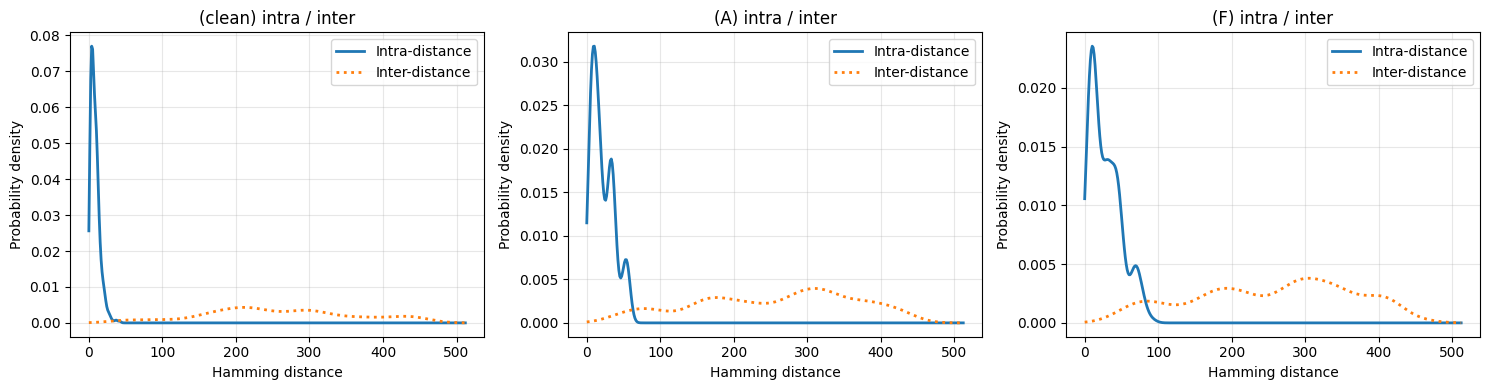

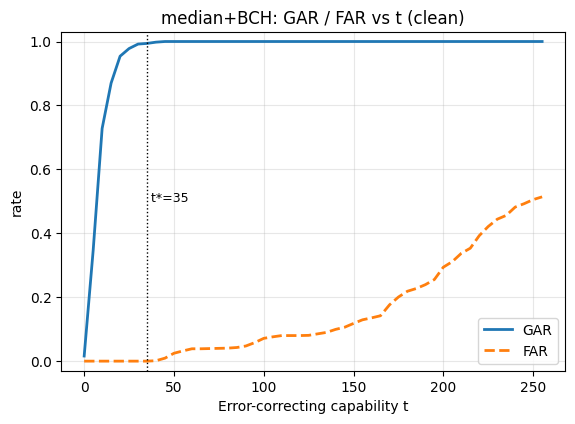

In [ ]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, len(conds), figsize=(5 * len(conds), 4), squeeze=False)
for ax, c in zip(axes[0], conds):
    g, i = dist[c]
    bch.plot_distance_distributions(g, i, bits=BITS, ax=ax,
                                    title=f"({c}) intra / inter")
fig.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4.4))
bch.plot_t_sweep(rows_clean, ax=ax, title="median+BCH: GAR / FAR vs t (clean)")
ax.axvline(T_STAR, color="k", ls=":", lw=1)
ax.text(T_STAR, 0.5, f" t*={T_STAR}", fontsize=9)
plt.show()

## Bias or variance?

Averaging shrinks zero-mean noise as 1/sqrt(n) but does nothing to a systematic
per-environment offset. If GAR at A/F saturates below 1.0 as n_verify grows,
the residual is bias, and no amount of extra packets fixes it — which is what
motivates channel-robust projection as future work.

Best figure-to-effort ratio in the paper.

 clean  E8 [0.99 1.   1.   1.   1.  ]   BCH [0.98  0.997 1.    1.    1.   ]
     A  E8 [0.703 0.78  0.797 0.8   0.8  ]   BCH [0.78  0.81  0.83  0.853 0.843]
     F  E8 [0.577 0.593 0.6   0.6   0.6  ]   BCH [0.61  0.66  0.673 0.687 0.693]


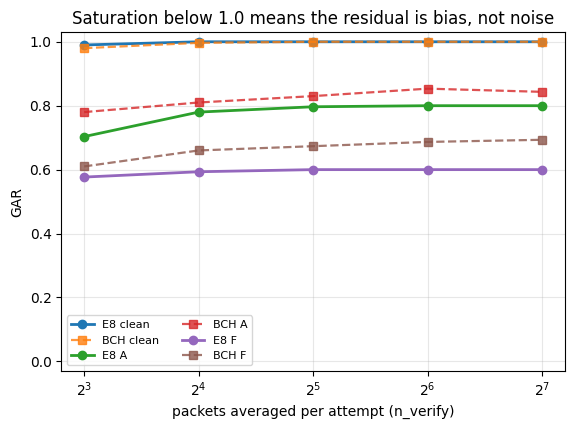

In [ ]:
NV = [8, 16, 32, 64, 128]
curves = {}
for c in conds:
    if c == "clean":
        Zg, yg, Bg = Z_tgt, y_tgt, B_tgt
        ne = N_ENROLL
    else:
        Zg, yg, Bg = Z_env[c], y_env[c], B_env[c]
        ne = 0
    ge, gb = [], []
    for nv in NV:
        r = v1.evaluate(db_e8, Zg, yg, Zg, yg, nv, E8_MARGIN, 30, 10, ne, SEED)
        ge.append(r.gar)
        g, i = bch.collect_distances(db_bch, Bg, yg, Bg, yg, nv, 30, 10, ne, SEED)
        gb.append(bch.evaluate_bch(g, i, T_STAR, nv, BITS, exact=False).gar)
    curves[c] = (ge, gb)
    print(f"{c:>6}  E8 {np.round(ge,3)}   BCH {np.round(gb,3)}")

fig, ax = plt.subplots(figsize=(6.5, 4.4))
for c in conds:
    ge, gb = curves[c]
    ax.plot(NV, ge, "o-", lw=2, label=f"E8 {c}")
    ax.plot(NV, gb, "s--", lw=1.6, alpha=.8, label=f"BCH {c}")
ax.set_xscale("log", base=2)
ax.set_xlabel("packets averaged per attempt (n_verify)")
ax.set_ylabel("GAR"); ax.set_ylim(-0.03, 1.03)
ax.set_title("Saturation below 1.0 means the residual is bias, not noise")
ax.grid(alpha=.3); ax.legend(fontsize=8, ncol=2)
plt.show()

## Leakage and entropy

The syndrome leak is fixed by the code: n - k parity bits, published regardless
of how much entropy the source has. Compare against the measured entropy of the
fingerprint — if leakage exceeds it, the residual is negative and the scheme is
a matcher, not a fuzzy extractor.

State the measurement floor explicitly. With this many devices the collision
estimator cannot resolve beyond roughly log2(#pairs) bits, and saying so is
stronger than having a reviewer derive it.

In [ ]:
print("BCH leakage across the sweep:")
for t in [10, 20, T_STAR, 43, 60]:
    try:
        p = bch.pick_bch(BITS, t, exact=True)
        print(f"  t={t:3d}  {p}")
    except Exception as e:
        print(f"  t={t:3d}  {e}")

# Entropy of the median-quantised fingerprint, measured the same way as for E8.
X_all = np.vstack([X_bg, X_tgt, X_imp])
y_all = np.concatenate([y_bg, y_tgt, y_imp])
B_all = sc.transform(X_all)

rng = np.random.default_rng(SEED)
reps = {}
for d in np.unique(y_all):
    z = B_all[y_all == d]
    reps[d] = np.stack([bch.median_quantize(
        z[rng.choice(len(z), min(N_VERIFY, len(z)), replace=False)].mean(0)[None])[0]
        for _ in range(20)])

hit = tot = 0
devs_all = np.unique(y_all)
for a in range(len(devs_all)):
    for b in range(a + 1, len(devs_all)):
        A, Bb = reps[devs_all[a]], reps[devs_all[b]]
        d = (A[:, None, :] != Bb[None, :, :]).sum(-1)
        hit += int((d == 0).sum()); tot += d.size
H2 = -np.log2(max(hit / tot, 1.0 / tot))
print(f"\nfingerprint collision entropy >= {H2:.1f} bits "
      f"({'AT FLOOR, ' if hit == 0 else ''}{tot} cross-device pairs)")
print(f"BCH publishes {bch.pick_bch(BITS, T_STAR, exact=True).leakage} parity bits at t={T_STAR}")

BCH leakage across the sweep:
  t= 10  BCH(n=1023, k=923, t=10) over GF(2^10) for a 512-bit fingerprint; helper publishes 100 parity bits
  t= 20  BCH(n=1023, k=828, t=20) over GF(2^10) for a 512-bit fingerprint; helper publishes 195 parity bits
  t= 35  BCH(n=1023, k=698, t=35) over GF(2^10) for a 512-bit fingerprint; helper publishes 325 parity bits
  t= 43  BCH(n=1023, k=628, t=43) over GF(2^10) for a 512-bit fingerprint; helper publishes 395 parity bits
  t= 60  BCH(n=2047, k=1409, t=60) over GF(2^11) for a 512-bit fingerprint; helper publishes 638 parity bits

fingerprint collision entropy >= 18.6 bits (AT FLOOR, 396000 cross-device pairs)
BCH publishes 325 parity bits at t=35


## DET matched FAR

  margin 0.20 done
  margin 0.30 done
  margin 0.40 done
  margin 0.50 done
  margin 0.65 done
  margin 0.80 done
  margin 1.00 done
  margin 1.20 done

GAR at matched FAR (each scheme at its own best knob setting)

   FAR<=    cond |  BCH GAR    t |   E8 GAR  margin
---------------------------------------------------
   0.000   clean |    0.998   38 |    1.000    0.40
   0.000       A |    0.642   26 |    0.916    0.30
   0.000       F |    0.656   34 |    0.942    0.30

   0.001   clean |    0.998   38 |    1.000    0.40
   0.001       A |    0.694   30 |    0.916    0.30
   0.001       F |    0.656   34 |    0.942    0.30

   0.005   clean |    1.000   42 |    1.000    0.30
   0.005       A |    0.804   34 |    0.916    0.30
   0.005       F |    0.696   38 |    0.942    0.30

   0.010   clean |    1.000   42 |    1.000    0.30
   0.010       A |    0.874   38 |    0.916    0.30
   0.010       F |    0.724   40 |    0.942    0.30



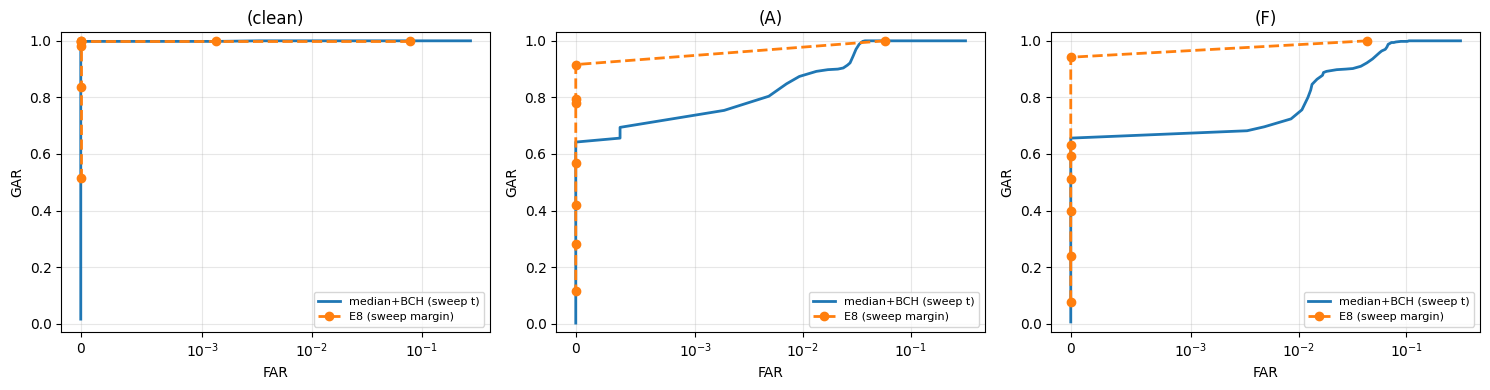

In [ ]:
# ============================================================
# DET / matched-FAR comparison  -- append as a new cell
# ============================================================
# GAR at different FAR is not a comparison. This sweeps each scheme's own
# knob (t for BCH, margin for E8) to trace GAR-vs-FAR per condition, then
# reports GAR at a common FAR target. This is the figure that decides
# whether E8 can be claimed as an improvement at all.

E8_MARGINS = [0.20, 0.30, 0.40, 0.50, 0.65, 0.80, 1.00, 1.20]
FAR_TARGETS = [0.0, 1e-3, 5e-3, 1e-2]

# ---- BCH operating curve: free, distances already collected ----
bch_curve = {}
for c, (g, i) in dist.items():
    pts = []
    for t in range(0, 200, 2):
        pts.append((np.mean(i <= t), np.mean(g <= t), t))
    bch_curve[c] = pts

# ---- E8 operating curve: re-enrol at each margin ----
e8_curve = {c: [] for c in conds}
for m in E8_MARGINS:
    dbm = v1.enroll_devices(Z_tgt, y_tgt, DEVICES, proj, N_ENROLL, N_VERIFY,
                            E8_NKEEP, m, seed=SEED)
    r = v1.evaluate(dbm, Z_tgt, y_tgt, Z_imp, y_imp, N_VERIFY, m,
                    50, 30, N_ENROLL, SEED)
    e8_curve["clean"].append((r.far, r.gar, m))
    for loc, Ze in Z_env.items():
        r = v1.evaluate(dbm, Ze, y_env[loc], Ze, y_env[loc], N_VERIFY, m,
                        50, 30, 0, SEED)
        e8_curve[loc].append((r.far, r.gar, m))
    print(f"  margin {m:.2f} done")

# ---- GAR at matched FAR ----
def gar_at(curve, far_max):
    ok = [(far, gar, k) for far, gar, k in curve if far <= far_max]
    return max(ok, key=lambda p: p[1]) if ok else (None, 0.0, None)

print("\nGAR at matched FAR (each scheme at its own best knob setting)\n")
hdr = f"{'FAR<=':>8} {'cond':>7} | {'BCH GAR':>8} {'t':>4} | {'E8 GAR':>8} {'margin':>7}"
print(hdr); print("-" * len(hdr))
for ft in FAR_TARGETS:
    for c in conds:
        _, gb, tb = gar_at(bch_curve[c], ft)
        _, ge, me = gar_at(e8_curve[c], ft)
        tb_s = f"{tb}" if tb is not None else "-"
        me_s = f"{me:.2f}" if me is not None else "-"
        print(f"{ft:8.3f} {c:>7} | {gb:8.3f} {tb_s:>4} | {ge:8.3f} {me_s:>7}")
    print()

# ---- DET plot ----
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, len(conds), figsize=(5 * len(conds), 4), squeeze=False)
for ax, c in zip(axes[0], conds):
    bf = [p[0] for p in bch_curve[c]]; bg = [p[1] for p in bch_curve[c]]
    ef = [p[0] for p in e8_curve[c]];  eg = [p[1] for p in e8_curve[c]]
    ax.plot(bf, bg, "-", lw=2, label="median+BCH (sweep t)")
    ax.plot(ef, eg, "o--", lw=2, label="E8 (sweep margin)")
    ax.set_xscale("symlog", linthresh=1e-3)
    ax.set_xlabel("FAR"); ax.set_ylabel("GAR")
    ax.set_ylim(-0.03, 1.03); ax.set_title(f"({c})")
    ax.grid(alpha=.3); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## Operating point on clean vs A/F

In [ ]:
# Operating point selected on CLEAN only, then transferred to A/F.
# This is the honest deployment number; the per-condition table is the oracle bound.
def pick_on_clean(curve, far_max):
    ok = [(f, g, k) for f, g, k in curve["clean"] if f <= far_max]
    return max(ok, key=lambda p: p[1])[2] if ok else None

def at_knob(curve, c, k):
    for f, g, kk in curve[c]:
        if kk == k:
            return g, f
    return float("nan"), float("nan")

print(f"{'FAR<=':>8} {'cond':>7} | {'BCH GAR':>8} {'FAR':>8} | {'E8 GAR':>8} {'FAR':>8}")
for ft in [0.0, 1e-3, 5e-3]:
    tb = pick_on_clean(bch_curve, ft)
    me = pick_on_clean(e8_curve, ft)
    print(f"  [BCH t*={tb}, E8 margin*={me} selected on clean]")
    for c in conds:
        gb, fb = at_knob(bch_curve, c, tb)
        ge, fe = at_knob(e8_curve, c, me)
        print(f"{ft:8.3f} {c:>7} | {gb:8.3f} {fb:8.5f} | {ge:8.3f} {fe:8.5f}")
    print()

   FAR<=    cond |  BCH GAR      FAR |   E8 GAR      FAR
  [BCH t*=38, E8 margin*=0.4 selected on clean]
   0.000   clean |    0.998  0.00000 |    1.000  0.00000
   0.000       A |    0.874  0.00926 |    0.794  0.00000
   0.000       F |    0.696  0.00481 |    0.630  0.00000

  [BCH t*=38, E8 margin*=0.4 selected on clean]
   0.001   clean |    0.998  0.00000 |    1.000  0.00000
   0.001       A |    0.874  0.00926 |    0.794  0.00000
   0.001       F |    0.696  0.00481 |    0.630  0.00000

  [BCH t*=42, E8 margin*=0.3 selected on clean]
   0.005   clean |    1.000  0.00333 |    1.000  0.00133
   0.005       A |    0.898  0.01704 |    0.916  0.00000
   0.005       F |    0.756  0.01074 |    0.942  0.00000



## Table 5 updated with optimal parameters

In [ ]:
print(len(Z_tgt), len(db_bch), conds, BITS)

NV = [8, 16, 32, 64, 128]
M_STAR, T_FIG = 0.30, 42          # same operating point as Table III

# re-enrol E8 at the Table III margin
db_fig = v1.enroll_devices(Z_tgt, y_tgt, DEVICES, proj, N_ENROLL, N_VERIFY,
                           E8_NKEEP, M_STAR, seed=SEED)

print(f"{'cond':>6} {'scheme':>5} " + " ".join(f"{nv:>7}" for nv in NV))
for c in conds:
    if c == "clean":
        # rogue devices are the impostors, same as Table III
        Zg, yg, Bg, ne = Z_tgt, y_tgt, B_tgt, N_ENROLL
        Zi_, yi_, Bi_ = Z_imp, y_imp, B_imp
    else:
        # same-environment impostors, same as Table III
        Zg, yg, Bg, ne = Z_env[c], y_env[c], B_env[c], 0
        Zi_, yi_, Bi_ = Z_env[c], y_env[c], B_env[c]

    ge, fe, gb, fb = [], [], [], []
    for nv in NV:
        r = v1.evaluate(db_fig, Zg, yg, Zi_, yi_, nv, M_STAR, 50, 30, ne, SEED)
        ge.append(r.gar); fe.append(r.far)
        g, i = bch.collect_distances(db_bch, Bg, yg, Bi_, yi_, nv, 50, 30, ne, SEED)
        rb = bch.evaluate_bch(g, i, T_FIG, nv, BITS, exact=False)
        gb.append(rb.gar); fb.append(rb.far)

    print(f"{c:>6}  E8   " + " ".join(f"{v:7.3f}" for v in ge))
    print(f"{'':>6} (FAR) " + " ".join(f"{v:7.4f}" for v in fe))
    print(f"{c:>6}  BCH  " + " ".join(f"{v:7.3f}" for v in gb))
    print(f"{'':>6} (FAR) " + " ".join(f"{v:7.4f}" for v in fb))

4000 10 ['clean', 'A', 'F'] 512
  cond scheme       8      16      32      64     128
 clean  E8     1.000   1.000   1.000   1.000   1.000
       (FAR)  0.0013  0.0013  0.0000  0.0000  0.0000
 clean  BCH    0.986   1.000   1.000   1.000   1.000
       (FAR)  0.0047  0.0033  0.0020  0.0000  0.0000
     A  E8     0.906   0.916   0.904   0.900   0.900
       (FAR)  0.0004  0.0000  0.0000  0.0000  0.0000
     A  BCH    0.884   0.898   0.900   0.900   0.900
       (FAR)  0.0174  0.0170  0.0170  0.0204  0.0204
     F  E8     0.898   0.942   0.978   1.000   1.000
       (FAR)  0.0000  0.0000  0.0000  0.0000  0.0000
     F  BCH    0.736   0.756   0.764   0.760   0.778
       (FAR)  0.0085  0.0107  0.0111  0.0111  0.0111
